# Validation, baseline and models for the aggregate CPU forecast

Purpose: build a fair rolling-origin test, then compare a baseline, a statistical model (ARIMA) and a machine-learning model (random forest) for `aggregate_cpu_utilization`, and tune the two models without touching the final 24 points.

- Inputs: `vm_cpu_readings.csv.gz` from release `data-v1`. Only the first 110 timestamps (the training window) are used; the last 24 are never loaded into any table or plot here.
- Code: the models, features and evaluation live in `src/cwfc` (`models.py`, `features.py`, `evaluate.py`) and are tested in `tests/`. This notebook only calls them and explains the results.
- Outputs: figures in `reports/figures/model_*.png` and tables in `reports/tables/model_*.csv` and `cv_*.csv`.
- Run: from an environment where the project is installed (the conda `atomity` environment or the venv from the README), `jupyter nbconvert --to notebook --execute --inplace notebooks/02_modeling.ipynb`. It takes a few minutes because it fits many forests.
- Terms: pp is percentage points; one step is 5 minutes; a forecast origin is the moment a forecast is issued; MAE is the mean absolute error and RMSE the root mean squared error, both in pp; high-load values are target values at or above the 80th percentile of the history available at that origin (as high as the busiest fifth of what had been seen so far), so the high-load metrics show how well peaks are forecast; a fold is one forecast origin with its 24-step window, and "folds better %" is the share of folds in which a model's MAE is lower than the baseline's.
- Multi-step strategy: the forest is direct, with a separate model for each of the 24 steps ahead, so errors are not fed back into later steps and no future inputs are needed. ARIMA forecasts its horizon by iterating its own one-step equation, with the hourly profile as a known future input. The baseline needs no strategy.
- Scope: this notebook covers validation, baselines, features and models (steps 4 and 5). `active_vm_count` is handled in section 7 because it is constant.

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cwfc import analysis as an
from cwfc import evaluate as ev
from cwfc import features as ft
from cwfc import models
from cwfc.data import ACTIVE_VM_COUNT, AGGREGATE_CPU, HOLDOUT_HORIZON, INTERVAL_SECONDS, SECONDS_PER_HOUR, STEPS_PER_HOUR, build_targets, load_readings, split_holdout
from cwfc.validation import origin_positions

an.set_plot_style()
N_JOBS = -1  # use every core for the rolling-origin runs; the results do not depend on it
REPORT_STEPS = (1, 6, 12, 24)  # forecast steps shown in the tables: 5, 30, 60 and 120 minutes ahead
METRIC_COLUMNS = ["MAE", "RMSE", "MAE ratio", "High-load MAE", "Folds better %"]

## 1. Validation design

What is checked: how the test is built, so that every forecast is made only from data that existed at its origin.

In [2]:
train, _ = split_holdout(build_targets(load_readings()))
series = train[AGGREGATE_CPU]
origins = origin_positions(len(series), HOLDOUT_HORIZON, ev.default_min_train(len(series), HOLDOUT_HORIZON), 1)
design = pd.Series(
    {
        "training rows": len(series),
        "forecast horizon (steps)": HOLDOUT_HORIZON,
        "first origin (history points)": origins[0],
        "last origin (history points)": origins[-1],
        "number of origins": len(origins),
        "high-load threshold": f"{ev.HIGH_LOAD_QUANTILE:.0%} quantile of each origin's own history",
    },
    name="value",
)
an.save_table(design, "model_cv_design")
display(design.to_frame())

,value
training rows,110
forecast horizon (steps),24
first origin (history points),48
last origin (history points),86
number of origins,39
high-load threshold,80% quantile of each origin's own history


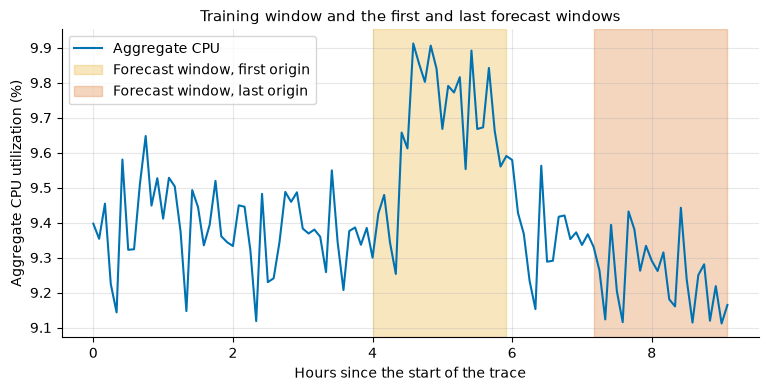

In [3]:
hours = an.elapsed_hours(series.index)
fig, ax = plt.subplots()
ax.plot(hours, series.to_numpy(), color=an.PALETTE["blue"], label="Aggregate CPU")
for origin, color, label in [(origins[0], "orange", "Forecast window, first origin"), (origins[-1], "red", "Forecast window, last origin")]:
    ax.axvspan(hours[origin], hours[origin + HOLDOUT_HORIZON - 1], color=an.PALETTE[color], alpha=0.25, label=label)
ax.set_xlabel("Hours since the start of the trace")
ax.set_ylabel("Aggregate CPU utilization (%)")
ax.set_title("Training window and the first and last forecast windows")
ax.legend()
an.save_figure(fig, "model_cv_design")
plt.show()

**Finding.** The test has 39 forecast origins. At each one the models see only the observations before it and forecast the next 24 steps (2 hours). The first origin has 48 points of history and the last has 86, so the forecast windows reach about hour 9. Neighbouring origins differ by one step, so the 39 tests overlap heavily and are not 39 independent samples.

**So what.** This copies real use: a forecast is issued at one moment, with only the past available, and is refitted when new data arrives. Because the origins overlap, a difference of a few thousandths of a pp between two models is weak evidence. The high-load threshold is recomputed from the history at each origin, so no future value leaks into it.

## 2. Baseline against simple references

What is checked: whether the history mean plus the average hourly profile is a strong baseline compared with three simple references: the last value (persistence), the previous hour repeated (seasonal-naive) and the plain history mean.

In [4]:
reference_result = ev.run_cv(series, {models.BASELINE_NAME: models.baseline_forecast, **models.reference_forecasters()}, n_jobs=N_JOBS)
references = ev.metrics_table(reference_result)
an.save_table(references.round(4), "model_references")
display(references[METRIC_COLUMNS].round(3))

,MAE,RMSE,MAE ratio,High-load MAE,Folds better %
Baseline,0.194,0.229,1.000,0.294,0.000
Persistence,0.238,0.294,1.224,0.234,38.462
Seasonal-naive,0.281,0.329,1.446,0.305,17.949
History mean,0.205,0.242,1.055,0.309,17.949


**Finding.** The baseline (history mean plus the average hourly profile) has the lowest MAE (0.194 pp) and RMSE (0.229 pp) of the four. The plain history mean is next (0.205), persistence is worse (0.238) and seasonal-naive is the worst (0.281). Persistence has the best high-load MAE (0.234) but loses to the baseline over all 24 steps.

**So what.** The baseline is a strong target, not a weak one: the level is stable and the hourly pattern is real, so the mean plus the profile is hard to beat. Seasonal-naive copies one noisy hour and so repeats that hour's noise, while the baseline averages many hours. Persistence is useful only for the first few steps (section 6). The models are judged against the baseline: a model has to beat an MAE of 0.194.

## 3. Feature engineering

What is checked: which inputs the forest gets, which of them carry signal at which horizon, and whether each can be computed at the forecast origin. The forest learns the correction to the baseline: its target is the actual value minus the history mean minus the hourly profile at the target position.

In [5]:
feature_table = pd.DataFrame(
    [
        ("lag_1", "latest observation at the origin", "yes, the last value seen"),
        ("lag_2", "observation one step before the origin", "yes, earlier than the origin"),
        ("lag_3", "observation two steps before the origin", "yes, earlier than the origin"),
        ("lag_12", "observation eleven steps before the origin (one hour before the first forecast step)", "yes, earlier than the origin"),
        ("mean_last_hour", "mean of the latest 12 observations", "yes, earlier than or at the origin"),
        ("last_change", "latest observation minus the one before", "yes, earlier than or at the origin"),
        ("profile_at_target", "average hourly profile at the target's position in the hour", "yes, built from the history only; the position follows from the target timestamp"),
        ("target_sin", "sine of the target's position in the hour", "yes, the timestamp of a future step is known"),
        ("target_cos", "cosine of the target's position in the hour", "yes, the timestamp of a future step is known"),
    ],
    columns=["feature", "definition", "available at the forecast origin"],
).set_index("feature")
assert tuple(feature_table.index) == ft.FEATURE_NAMES
an.save_table(feature_table, "model_feature_table")
display(feature_table)

,definition,available at the forecast origin
feature,,
lag_1,latest observation at the origin,"yes, the last value seen"
lag_2,observation one step before the origin,"yes, earlier than the origin"
lag_3,observation two steps before the origin,"yes, earlier than the origin"
lag_12,observation eleven steps before the origin (on...,"yes, earlier than the origin"
mean_last_hour,mean of the latest 12 observations,"yes, earlier than or at the origin"
last_change,latest observation minus the one before,"yes, earlier than or at the origin"
profile_at_target,average hourly profile at the target's positio...,"yes, built from the history only; the position..."
target_sin,sine of the target's position in the hour,"yes, the timestamp of a future step is known"
target_cos,cosine of the target's position in the hour,"yes, the timestamp of a future step is known"


,1,6,12,24
lag_1,0.81,0.59,0.18,-0.28
lag_2,0.76,0.51,0.15,-0.31
lag_3,0.72,0.46,0.11,-0.30
lag_12,0.17,-0.02,-0.23,-0.45
mean_last_hour,0.69,0.34,-0.04,-0.46
last_change,0.08,0.11,0.04,0.04
profile_at_target,-0.05,-0.05,-0.04,-0.05
target_sin,0.06,0.06,0.05,0.04
target_cos,-0.04,-0.05,-0.06,-0.09


,lag_1,lag_2,lag_3,lag_12,mean_last_hour,last_change,profile_at_target,target_sin,target_cos
lag_1,1.00,0.68,0.62,0.12,0.66,0.41,-0.06,0.21,-0.08
lag_2,0.68,1.00,0.67,0.18,0.71,-0.38,-0.16,0.16,-0.17
lag_3,0.62,0.67,1.00,0.34,0.75,-0.05,0.00,0.08,-0.23
lag_12,0.12,0.18,0.34,1.00,0.62,-0.07,-0.22,0.26,0.04
mean_last_hour,0.66,0.71,0.75,0.62,1.00,-0.05,-0.02,0.03,-0.01
last_change,0.41,-0.38,-0.05,-0.07,-0.05,1.00,0.12,0.06,0.10
profile_at_target,-0.06,-0.16,0.00,-0.22,-0.02,0.12,1.00,-0.45,0.11
target_sin,0.21,0.16,0.08,0.26,0.03,0.06,-0.45,1.00,0.00
target_cos,-0.08,-0.17,-0.23,0.04,-0.01,0.10,0.11,0.00,1.00


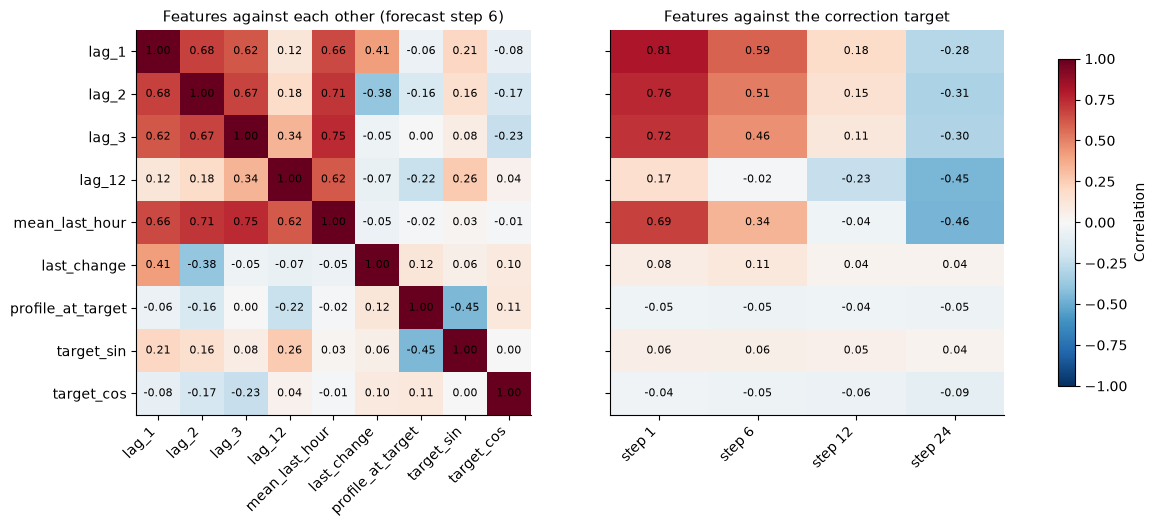

In [6]:
correlations = ft.correlation_with_target(series, REPORT_STEPS)
feature_matrix = ft.training_table(series, 6).drop(columns=ft.TARGET).corr()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
image = an.plot_heatmap(axes[0], feature_matrix, "Features against each other (forecast step 6)")
an.plot_heatmap(axes[1], correlations.rename(columns=lambda step: f"step {step}"), "Features against the correction target")
axes[1].tick_params(labelleft=False)
fig.colorbar(image, ax=axes, label="Correlation", shrink=0.85)
an.save_figure(fig, "model_feature_correlation")
an.save_table(correlations.round(3), "model_feature_correlation")
display(correlations.round(2))
display(feature_matrix.round(2))
plt.show()

**Finding.** At step 1 the correction target (what the baseline misses) is strongly related to the latest values: 0.81 with lag_1, 0.76 with lag_2, 0.72 with lag_3 and 0.69 with the one-hour mean. The link fades with the horizon: for lag_1 it is 0.59 at step 6 and 0.18 at step 12, and it turns negative at step 24 (-0.28 for lag_1, -0.45 for lag_12 and -0.46 for the one-hour mean). The last change, the profile value and the two hour-position terms stay close to zero (absolute value at most 0.11) at every step shown. The recent values are also strongly related to each other (0.62 to 0.75 among lag_1, lag_2, lag_3 and the one-hour mean).

**So what.** Where the series is now is the signal. A recent value above the baseline predicts a value above it in the next few minutes, but two hours later it predicts a value below it (the series falls back towards its usual level). A baseline that ignores the recent past cannot capture either effect. The recent values carry overlapping information, so a few of them should be enough; the ablation below tests that. The profile and hour-position terms add little because the target already has the profile subtracted. These correlations come from 75 to 98 overlapping rows (depending on the step), and the sign change at step 24 may be driven by the one main high-load episode, so they only guide the choice; the out-of-sample test decides.

Ablation: the forest is rerun with different feature sets to see which inputs actually help out of sample. The correlation view above is only a guide; this test decides.

In [7]:
FEATURE_SETS = {
    "all nine features": ft.FEATURE_NAMES,
    "lags 1, 2, 3, 12 and mean_last_hour": ("lag_1", "lag_2", "lag_3", "lag_12", "mean_last_hour"),
    "lag_1, lag_12, mean_last_hour (selected)": models.FOREST_FEATURES,
    "lag_1 and mean_last_hour": ("lag_1", "mean_last_hour"),
    "lag_12 and mean_last_hour": ("lag_12", "mean_last_hour"),
    "no lag features (profile and hour position only)": ("profile_at_target", "target_sin", "target_cos"),
}
ablation_forecasters = {label: partial(models.forest_forecast, params=models.ForestParams(features=features)) for label, features in FEATURE_SETS.items()}
ablation_result = ev.run_cv(series, {models.BASELINE_NAME: models.baseline_forecast, **ablation_forecasters}, n_jobs=N_JOBS)
ablation = ev.metrics_table(ablation_result)
an.save_table(ablation.round(4), "model_feature_ablation")
display(ablation[METRIC_COLUMNS].round(3))

,MAE,RMSE,MAE ratio,High-load MAE,Folds better %
Baseline,0.194,0.229,1.000,0.294,0.000
all nine features,0.181,0.233,0.930,0.303,53.846
"lags 1, 2, 3, 12 and mean_last_hour",0.180,0.233,0.924,0.303,53.846
"lag_1, lag_12, mean_last_hour (selected)",0.177,0.232,0.913,0.304,53.846
lag_1 and mean_last_hour,0.180,0.234,0.925,0.305,51.282
lag_12 and mean_last_hour,0.188,0.240,0.968,0.313,48.718
no lag features (profile and hour position only),0.221,0.252,1.136,0.307,0.000


**Finding.** The lag features are what makes the forest work: without them the MAE is 0.221 pp, worse than the baseline's 0.194, and it beats the baseline in no fold. With them the MAE is 0.177 to 0.181 for four of the five sets, and 0.188 when lag_1 is left out (lag_12 and mean_last_hour only). The selected set (lag_1, lag_12, mean_last_hour) has the lowest MAE (0.177) with a third of the inputs; adding lags 2 and 3, the last change, the profile value and the hour-position terms gives 0.180 to 0.181.

**So what.** The useful information is a few numbers about the recent level: the latest value and the mean of the last hour. The first four sets differ only between 0.177 and 0.181, which is inside the noise of 39 overlapping origins, so the choice rests on simplicity: fewer inputs mean less risk of fitting noise in a 110-point series. Of the three selected inputs, lag_1 matters most: without it the MAE is 0.188, without lag_12 it is 0.180, and with all three it is 0.177. The other features stay in `features.py` because they were tested and the correlation view uses them.

## 4. Tuning the statistical model (ARIMA)

What is checked: which autoregressive order (p), moving-average order (q) and regressor setting give the lowest cross-validated error. d is 0 (no differencing) because the EDA found a sign of over-differencing when the series is differenced once. "With profile" adds the hourly profile as an extra input. A fit that fails or warns falls back to the baseline, so the table counts the origins where the forecast equals the baseline exactly; a setting that falls back often is not really being tested.

In [8]:
ARIMA_SPECS = [(p, q, use_profile) for p in (1, 2, 3, 4, 6) for q in (0, 1) for use_profile in (True, False)]


def arima_label(p: int, q: int, use_profile: bool) -> str:
    """Return the table label of an ARIMA setting."""
    return f"ARIMA({p},0,{q}) {'with' if use_profile else 'without'} profile"


arima_grid = {arima_label(*spec): partial(models.arima_forecast, order=(spec[0], 0, spec[1]), use_profile=spec[2]) for spec in ARIMA_SPECS}
arima_result = ev.run_cv(series, {models.BASELINE_NAME: models.baseline_forecast, **arima_grid}, n_jobs=N_JOBS)
arima_table = ev.metrics_table(arima_result)
baseline_forecasts = arima_result.predictions[models.BASELINE_NAME]
arima_table["Fallback origins"] = [
    np.nan if name == models.BASELINE_NAME else int((arima_result.predictions[name] == baseline_forecasts).all(axis=1).sum()) for name in arima_table.index
]
arima_table = arima_table.sort_values("MAE")
an.save_table(arima_table.round(4), "model_arima_grid")
display(arima_table[[*METRIC_COLUMNS, "Fallback origins"]].round(3))

,MAE,RMSE,MAE ratio,High-load MAE,Folds better %,Fallback origins
"ARIMA(3,0,1) with profile",0.175,0.214,0.899,0.278,51.282,19.0
"ARIMA(4,0,1) with profile",0.177,0.218,0.911,0.293,41.026,22.0
"ARIMA(1,0,0) with profile",0.179,0.213,0.919,0.238,66.667,1.0
"ARIMA(4,0,0) with profile",0.182,0.218,0.938,0.242,66.667,1.0
"ARIMA(6,0,0) with profile",0.182,0.219,0.939,0.255,61.538,4.0
"ARIMA(2,0,0) with profile",0.185,0.220,0.951,0.248,61.538,2.0
"ARIMA(1,0,1) with profile",0.185,0.220,0.953,0.233,66.667,0.0
"ARIMA(1,0,1) without profile",0.186,0.227,0.957,0.247,48.718,11.0
"ARIMA(3,0,0) with profile",0.188,0.224,0.965,0.235,66.667,1.0
"ARIMA(3,0,0) without profile",0.190,0.231,0.979,0.247,48.718,0.0


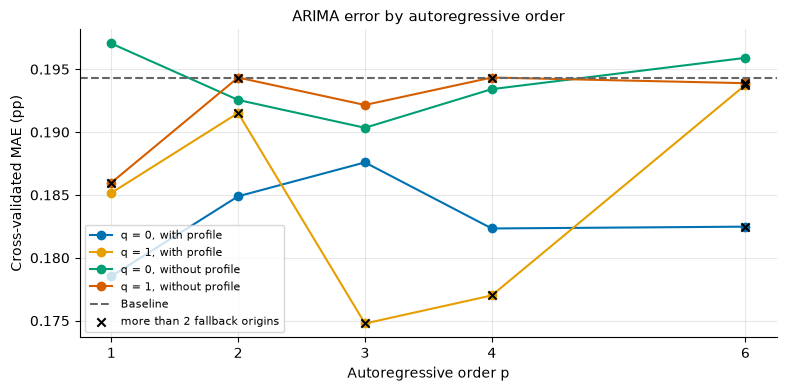

In [9]:
MAX_FALLBACK_ORIGINS = 2
fig, ax = plt.subplots()
for q, use_profile in [(0, True), (1, True), (0, False), (1, False)]:
    names = [arima_label(p, q, use_profile) for p in (1, 2, 3, 4, 6)]
    ax.plot((1, 2, 3, 4, 6), arima_table.loc[names, "MAE"], marker="o", label=f"q = {q}, {'with' if use_profile else 'without'} profile")
    unreliable = arima_table.loc[names, "Fallback origins"] > MAX_FALLBACK_ORIGINS
    ax.scatter(np.array((1, 2, 3, 4, 6))[unreliable.to_numpy()], arima_table.loc[names, "MAE"][unreliable], marker="x", color="black", zorder=3)
ax.axhline(arima_table.loc[models.BASELINE_NAME, "MAE"], color=an.PALETTE["grey"], linestyle="--", label="Baseline")
ax.scatter([], [], marker="x", color="black", label=f"more than {MAX_FALLBACK_ORIGINS} fallback origins")
ax.set_xticks((1, 2, 3, 4, 6))
ax.set_xlabel("Autoregressive order p")
ax.set_ylabel("Cross-validated MAE (pp)")
ax.set_title("ARIMA error by autoregressive order")
ax.legend(fontsize=8)
an.save_figure(fig, "model_arima_tuning")
plt.show()

**Finding.** The lowest MAE belongs to ARIMA(3,0,1) with the profile (0.175), but its fit fell back to the baseline at 19 of 39 origins (ARIMA(4,0,1) with the profile at 22), so that number mixes ARIMA and baseline forecasts and is not trusted. Among settings that fit reliably (at most 2 fallback origins), ARIMA(1,0,0) with the profile has the lowest MAE (0.179) and the lowest RMSE (0.213), the fit failed at 1 origin, and it beats the baseline in 66.7% of origins. Without the profile the same model is worse than the baseline (0.197 against 0.194). Higher autoregressive orders with the profile do not help (0.182 to 0.188).

**So what.** The hourly profile is what makes the model work. The EDA saw significant partial autocorrelation at lags 1 to 3, probably because the hourly pattern was still inside the series; once the profile is a separate input, one autoregressive term (the latest deviation from the profile) is enough, and higher orders do not lower the error. Fewer parameters is the safer choice with 110 points. Selection rule: lowest MAE and RMSE among settings with at most 2 fallback origins, which picks ARIMA(1,0,0) with the profile. Moving-average terms were fragile when combined with two or more autoregressive terms (fits failed or warned at 19 to 35 of 39 origins); ARIMA(1,0,1) with the profile fitted at every origin but was no better (0.185), so they are not used.

## 5. Tuning the machine-learning model (random forest)

What is checked: how complex the forest should be. The main setting is the minimum share of the training rows in each leaf (a larger share gives simpler trees). For each setting the table shows the cross-validated error and the in-sample error on the rows the forest was trained on. A large gap means overfitting; an error above the baseline's at the simple end means underfitting.

In [10]:
LEAF_FRACTIONS = (0.02, 0.05, 0.1, 0.15, 0.2, 0.3)
leaf_forecasters = {f"leaf {leaf:.0%}": partial(models.forest_forecast, params=models.ForestParams(min_samples_leaf=leaf)) for leaf in LEAF_FRACTIONS}
leaf_result = ev.run_cv(series, {models.BASELINE_NAME: models.baseline_forecast, **leaf_forecasters}, n_jobs=N_JOBS)
leaf_table = ev.metrics_table(leaf_result)
in_sample = [ev.in_sample_table(series, params=models.ForestParams(min_samples_leaf=leaf), n_jobs=N_JOBS)["forest"].mean() for leaf in LEAF_FRACTIONS]
leaf_table["In-sample MAE"] = [np.nan, *in_sample]
an.save_table(leaf_table.round(4), "model_forest_leaf")
display(leaf_table[[*METRIC_COLUMNS, "In-sample MAE"]].round(3))

,MAE,RMSE,MAE ratio,High-load MAE,Folds better %,In-sample MAE
Baseline,0.194,0.229,1.000,0.294,0.000,NaN
leaf 2%,0.178,0.232,0.915,0.279,58.974,0.046
leaf 5%,0.179,0.234,0.921,0.291,58.974,0.063
leaf 10%,0.179,0.234,0.919,0.298,53.846,0.081
leaf 15%,0.177,0.232,0.913,0.304,53.846,0.092
leaf 20%,0.179,0.232,0.921,0.307,56.410,0.100
leaf 30%,0.194,0.236,1.001,0.305,51.282,0.113


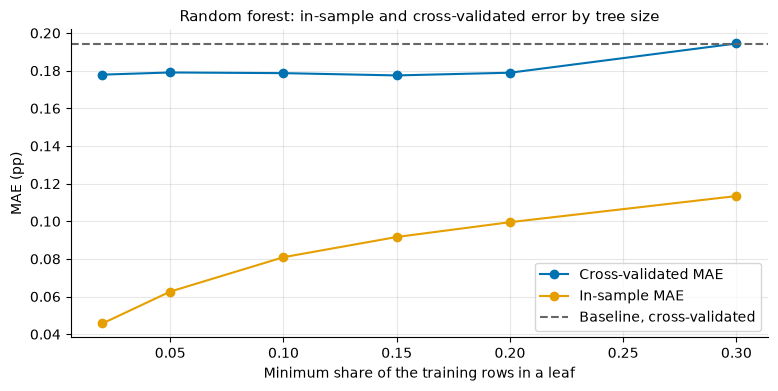

In [11]:
fig, ax = plt.subplots()
ax.plot(LEAF_FRACTIONS, leaf_table["MAE"].iloc[1:], marker="o", label="Cross-validated MAE")
ax.plot(LEAF_FRACTIONS, leaf_table["In-sample MAE"].iloc[1:], marker="o", label="In-sample MAE")
ax.axhline(leaf_table.loc[models.BASELINE_NAME, "MAE"], color=an.PALETTE["grey"], linestyle="--", label="Baseline, cross-validated")
ax.set_xlabel("Minimum share of the training rows in a leaf")
ax.set_ylabel("MAE (pp)")
ax.set_title("Random forest: in-sample and cross-validated error by tree size")
ax.legend()
an.save_figure(fig, "model_forest_tuning")
plt.show()

**Finding.** The cross-validated MAE is almost flat (0.177 to 0.179) for leaf shares from 2% to 20%, and rises to 0.194, the baseline's level, at 30%. The in-sample MAE rises steadily from 0.046 to 0.113 as leaves grow. The 2% forest fits its own rows about four times better than it forecasts new ones (0.046 against 0.178), the 15% forest about twice as well (0.092 against 0.177). In the table, MAE is the cross-validated MAE (the error on origins the forest was not trained on) and In-sample MAE is the error on its own training rows. The 15% setting has the lowest cross-validated MAE (0.177, against 0.178 at 2% and 0.179 elsewhere in the flat region). The RMSE is 0.232 at 2%, 15% and 20% and 0.234 at 5% and 10%, so it does not separate the settings either. Small leaves track peaks a little better (high-load MAE 0.279 at 2%, 0.304 at 15%).

**So what.** Very small leaves let each tree memorise its training rows: the in-sample error is tiny but new data are no better forecast, which is overfitting. At 30% each leaf holds nearly a third of the rows, the forest cannot tell situations apart and returns an almost constant correction, so it is no better than the baseline: underfitting. In between the validation error hardly moves (0.177 to 0.179 is inside the noise of 39 overlapping origins), so the choice rests on the other evidence: 15% is in the middle of the flat region, memorises much less than the small leaves (in-sample error 0.092 against 0.046 at 2%), is far from the underfitting point at 30%, and as a share it scales with the amount of history. The cost is a worse peak error than the smallest leaves (0.304 against 0.279 at 2%, and above the baseline's 0.294), the one place where smaller leaves help, and one reason the forest is not the recommended model.

The other settings are compared with the leaf share fixed at the chosen value.

In [12]:
FOREST_SETTINGS = {
    "selected: 100 trees, all features per split": models.ForestParams(),
    "50 trees": models.ForestParams(n_estimators=50),
    "200 trees": models.ForestParams(n_estimators=200),
    "two of three features per split": models.ForestParams(max_features=0.67),
    "maximum depth 2": models.ForestParams(max_depth=2),
    "maximum depth 4": models.ForestParams(max_depth=4),
}
setting_result = ev.run_cv(
    series,
    {models.BASELINE_NAME: models.baseline_forecast, **{label: partial(models.forest_forecast, params=params) for label, params in FOREST_SETTINGS.items()}},
    n_jobs=N_JOBS,
)
setting_table = ev.metrics_table(setting_result)
an.save_table(setting_table.round(4), "model_forest_settings")
display(setting_table[METRIC_COLUMNS].round(3))

,MAE,RMSE,MAE ratio,High-load MAE,Folds better %
Baseline,0.194,0.229,1.000,0.294,0.000
"selected: 100 trees, all features per split",0.177,0.232,0.913,0.304,53.846
50 trees,0.177,0.232,0.912,0.304,51.282
200 trees,0.178,0.232,0.916,0.304,53.846
two of three features per split,0.186,0.234,0.955,0.302,53.846
maximum depth 2,0.177,0.232,0.913,0.304,53.846
maximum depth 4,0.177,0.232,0.913,0.304,53.846


**Finding.** 50, 100 and 200 trees give the same MAE (0.177 to 0.178), and limiting the depth to 2 or 4 changes nothing (0.177). Letting each split see only two of the three inputs is worse (0.186).

**So what.** More or deeper trees buy nothing here: the 15% leaf rule already keeps the trees shallow. With only three inputs, hiding one from a split mostly removes useful information. The cheap, stable setting (100 trees, all inputs at each split) is kept.

## 6. Final comparison

What is checked: the three tuned models and the three references on the same 39 origins, every required metric, the error by forecast step, and the behaviour during the high-load episode.

In [13]:
result = ev.run_cv(series, {**models.candidate_forecasters(), **models.reference_forecasters()}, n_jobs=N_JOBS)
metrics = ev.metrics_table(result)
horizon_mae = ev.horizon_table(result)
an.save_table(metrics.round(4), ev.METRICS_TABLE_NAME)
an.save_table(horizon_mae.round(4), ev.HORIZON_TABLE_NAME)
display(metrics.round(3))

,MAE,RMSE,MAE ratio,Improvement %,High-load MAE,High-load RMSE,High-load bias,Fold MAE std,Folds better %
Baseline,0.194,0.229,1.000,0.000,0.294,0.326,0.294,0.053,0.000
ARIMA,0.179,0.213,0.919,8.130,0.238,0.284,0.223,0.058,66.667
Random forest,0.177,0.232,0.913,8.676,0.304,0.338,0.299,0.090,53.846
Persistence,0.238,0.294,1.224,-22.369,0.234,0.284,0.107,0.104,38.462
Seasonal-naive,0.281,0.329,1.446,-44.624,0.305,0.342,0.238,0.087,17.949
History mean,0.205,0.242,1.055,-5.493,0.309,0.334,0.309,0.055,17.949


,Baseline,ARIMA,Random forest,Persistence,Seasonal-naive,History mean
step,,,,,,
1,0.198,0.082,0.134,0.119,0.274,0.208
6,0.228,0.195,0.232,0.200,0.280,0.241
12,0.194,0.196,0.193,0.223,0.223,0.209
24,0.166,0.175,0.125,0.274,0.274,0.174


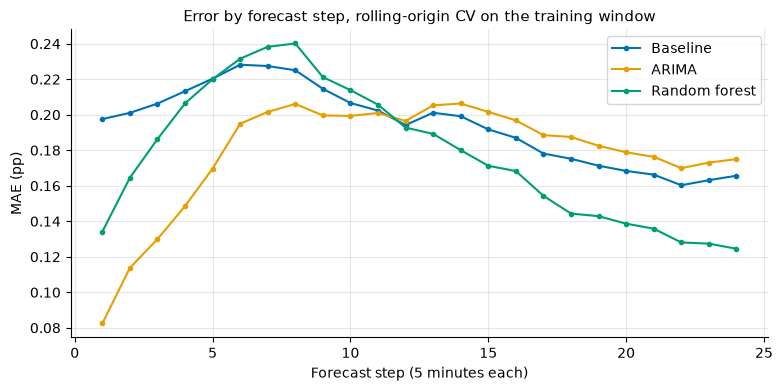

In [14]:
candidates = list(models.candidate_forecasters())
fig = ev.plot_horizon_errors(horizon_mae[candidates])
an.save_figure(fig, "model_horizon_mae")
display(horizon_mae.loc[list(REPORT_STEPS)].round(3))
plt.show()

In [15]:
horizon_rmse = ev.horizon_table(result, "rmse")
an.save_table(horizon_rmse.round(4), ev.HORIZON_RMSE_TABLE_NAME)
display(horizon_rmse.loc[list(REPORT_STEPS)].round(3))


,Baseline,ARIMA,Random forest,Persistence,Seasonal-naive,History mean
step,,,,,,
1,0.243,0.138,0.185,0.160,0.325,0.250
6,0.267,0.237,0.285,0.255,0.327,0.279
12,0.224,0.224,0.237,0.272,0.272,0.244
24,0.190,0.195,0.180,0.322,0.322,0.203


**Finding.** ARIMA wins the short range: at step 1 its MAE is 0.082 against 0.134 for the forest and 0.198 for the baseline, and at step 6 it is 0.195 against 0.232 and 0.228. Around step 12 the three models tie (0.193 to 0.196). At step 24 the forest is best (0.125 against 0.166 for the baseline and 0.175 for ARIMA). Persistence (repeat the latest value at every step; a reference, not one of the three models) is second best at step 1 (0.119) but is the worst, or tied for the worst, from step 12 on (0.223 at step 12, 0.274 at step 24, level with seasonal-naive, which repeats the same latest value at those two steps). The second table gives the RMSE at the same steps and tells the same story: at step 1 ARIMA is best (0.138, against 0.185 for the forest and 0.243 for the baseline), at step 6 ARIMA is again best (0.237 against 0.267 for the baseline and 0.285 for the forest), at step 12 the baseline and ARIMA tie (0.224) and the forest is worse (0.237), and at step 24 the forest is best (0.180 against 0.190 for the baseline and 0.195 for ARIMA).

**So what.** Recent data are valuable a few steps ahead and lose their value with distance. ARIMA carries the latest value forward, so it dominates early. By step 24 that carry-over has died out and ARIMA is a little worse than the baseline (0.175 against 0.166). The forest uses the last hour's mean and learned that a high recent hour is followed by a below-baseline value two hours later (the negative correlation above), so it is best at the far end. Its RMSE is higher than the baseline's at steps 6 and 12, which means its misses are larger than the baseline's in the middle of the horizon even where its average error is similar. A policy that used ARIMA for the first hour and the forest for the second might do better than either; it is not tested or adopted here, because the task asks for one statistical and one machine-learning model and a switch adds complexity.

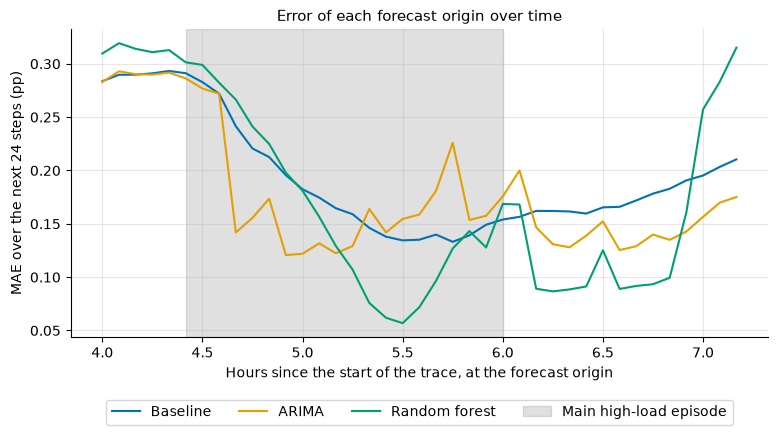

In [16]:
EPISODE_MIN_STEPS = 6  # high-load runs of at least 30 minutes form the main episode, as in the EDA
runs = an.peak_periods(series, series.quantile(ev.HIGH_LOAD_QUANTILE))
long_runs = runs[runs["n_steps"] >= EPISODE_MIN_STEPS]
since_start = pd.Series(hours, index=series.index)
episode_hours = (since_start[long_runs["start"].min()], since_start[long_runs["end"].max()])
fold_mae = ev.fold_table(result)[candidates]
fold_hours = (fold_mae.index - series.index[0]) / 3600
fig, ax = plt.subplots()
for name in candidates:
    ax.plot(fold_hours, fold_mae[name], label=name)
ax.axvspan(*episode_hours, color=an.PALETTE["grey"], alpha=0.2, label="Main high-load episode")
ax.set_xlabel("Hours since the start of the trace, at the forecast origin")
ax.set_ylabel("MAE over the next 24 steps (pp)")
ax.set_title("Error of each forecast origin over time")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)
an.save_figure(fig, "model_fold_mae")
plt.show()

In [17]:
WINDOW_HOURS = HOLDOUT_HORIZON * INTERVAL_SECONDS / SECONDS_PER_HOUR
overlaps = (fold_hours <= episode_hours[1]) & (fold_hours + WINDOW_HOURS >= episode_hours[0])
groups = pd.Series(np.where(overlaps, "windows overlapping the episode", "other windows"), index=fold_mae.index)
episode_mae = fold_mae.groupby(groups).mean()
episode_mae["origins"] = groups.value_counts()
an.save_table(episode_mae.round(4), "model_episode_mae")
print(f"main high-load episode: hour {episode_hours[0]:.1f} to {episode_hours[1]:.1f}")
display(episode_mae.round(3))

main high-load episode: hour 4.4 to 6.0


,Baseline,ARIMA,Random forest,origins
other windows,0.176,0.148,0.146,14
windows overlapping the episode,0.205,0.196,0.195,25


**Finding.** The 25 origins whose 24-step window overlaps the main high-load episode (hour 4.4 to 6.0) are harder for every model: the MAE is 0.205 for the baseline, 0.196 for ARIMA and 0.195 for the forest, against 0.176, 0.148 and 0.146 for the other 14 origins. In the chart all three models start with their largest errors at the earliest origins, just before the level rises. ARIMA's error then falls sooner than the baseline's, and the forest's error falls furthest in the middle of the episode but climbs steeply again at the last origins.

**So what.** A level shift that has not started yet cannot be forecast by any of these models, so the first errors are unavoidable. Once the shift has started, ARIMA reacts within a few steps because it uses the latest value, while the baseline reacts only slowly because it averages the whole history. The forest's late rise in error is probably because its corrections, learned from the high part of the trace, do not fit when the level moves back down. It is a warning that the forest is the less dependable of the two models when the level changes.

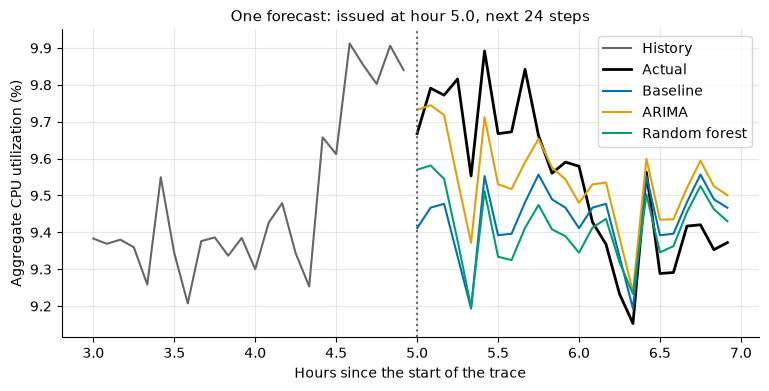

In [18]:
EXAMPLE_ORIGIN = 60  # a forecast issued at hour 5.0, inside the high-load episode
row = list(result.origins).index(EXAMPLE_ORIGIN)
window = hours[EXAMPLE_ORIGIN : EXAMPLE_ORIGIN + HOLDOUT_HORIZON]
fig, ax = plt.subplots()
ax.plot(hours[EXAMPLE_ORIGIN - HOLDOUT_HORIZON : EXAMPLE_ORIGIN], series.iloc[EXAMPLE_ORIGIN - HOLDOUT_HORIZON : EXAMPLE_ORIGIN], color=an.PALETTE["grey"], label="History")
ax.plot(window, result.actual[row], color="black", linewidth=2, label="Actual")
for name in candidates:
    ax.plot(window, result.predictions[name][row], label=name)
ax.axvline(hours[EXAMPLE_ORIGIN], color=an.PALETTE["grey"], linestyle=":")
ax.set_xlabel("Hours since the start of the trace")
ax.set_ylabel("Aggregate CPU utilization (%)")
ax.set_title("One forecast: issued at hour 5.0, next 24 steps")
ax.legend()
an.save_figure(fig, "model_example_forecast")
plt.show()

In [19]:
example_errors = {}
for name in candidates:
    error = result.actual[row] - result.predictions[name][row]
    example_errors[name] = {"MAE": np.abs(error).mean(), "Bias, first hour": error[:STEPS_PER_HOUR].mean(), "Bias, second hour": error[STEPS_PER_HOUR:].mean()}
example_errors = pd.DataFrame(example_errors).T
an.save_table(example_errors.round(4), "model_example_errors")
display(example_errors.round(3))

,MAE,"Bias, first hour","Bias, second hour"
Baseline,0.182,0.272,-0.063
ARIMA,0.122,0.105,-0.110
Random forest,0.181,0.280,-0.030


**Finding.** This forecast was issued at hour 5.0, just after the CPU level had risen (grey history). Bias is the average of actual minus forecast, so a positive bias means the forecast was too low. In the first hour the actual values stayed high: the baseline and the forest were too low by 0.272 and 0.280 pp on average and ARIMA by only 0.105 pp. In the second hour the actual values fell back and all three forecasts were slightly too high (bias of -0.063 for the baseline, -0.110 for ARIMA and -0.030 for the forest). Over all 24 steps the MAE is 0.122 pp for ARIMA, 0.182 pp for the baseline and 0.181 pp for the forest.

**So what.** ARIMA wins this forecast because of the first hour. It starts from the latest observations, which are high, and carries part of that level forward, while the baseline returns towards the long-run average and the hourly pattern. The forest, although it also sees recent values, ends up almost the same as the baseline here (MAE 0.181 against 0.182). The same habit costs ARIMA in the second hour: when the level falls back it stays too high for longer (bias of -0.110, the largest of the three), but this loss is smaller than its gain in the first hour. For capacity planning a forecast that is too low is the more serious mistake, because it can leave too little capacity at a peak, while a forecast that is too high only wastes some spare capacity. One forecast is an illustration, not evidence; the evidence is the metrics table in this section.

Fit check: does either model overfit or underfit? The in-sample error is the error on the data the model was fitted to; it is compared with the cross-validated error, which is the error on origins the model has not seen. Overfitting shows as a training error far below the test error. Underfitting shows as a high error on both and as structure left in the residuals (the part of the series the model did not explain). The first table gives the totals. The figure that follows has three panels: the in-sample and cross-validated MAE of the forest and the baseline at each forecast step (left), the ARIMA residuals over time (middle) and their autocorrelation, where a bar inside the shaded band cannot be told apart from random noise (right).

In [20]:
residuals = pd.Series(models.arima_residuals(series))
forest_fit = ev.in_sample_table(series, n_jobs=N_JOBS)
fit_check = pd.DataFrame(
    {
        "In-sample MAE": [residuals.abs().mean(), forest_fit["forest"].mean(), forest_fit["baseline"].mean()],
        "Cross-validated MAE": [horizon_mae.loc[1, models.ARIMA_NAME], metrics.loc[models.FOREST_NAME, "MAE"], metrics.loc[models.BASELINE_NAME, "MAE"]],
    },
    index=["ARIMA (one step ahead)", "Random forest (all steps)", "Baseline (all steps)"],
)
fit_check["Cross-validated / in-sample"] = fit_check["Cross-validated MAE"] / fit_check["In-sample MAE"]
an.save_table(fit_check.round(4), "model_fit_check")
an.save_table(an.ljung_box(residuals).round(4), "model_arima_residual_test")
display(fit_check.round(3))
display(an.ljung_box(residuals).round(3))

,In-sample MAE,Cross-validated MAE,Cross-validated / in-sample
ARIMA (one step ahead),0.061,0.082,1.360
Random forest (all steps),0.092,0.177,1.937
Baseline (all steps),0.126,0.194,1.537


,statistic,p_value
lag,,
5,7.446,0.190
10,11.586,0.314
20,23.823,0.250


,"Forest, in-sample","Forest, cross-validated","Baseline, in-sample","Baseline, cross-validated"
step,,,,
1,0.059,0.134,0.114,0.198
6,0.091,0.232,0.120,0.228
12,0.107,0.193,0.126,0.194
24,0.072,0.125,0.138,0.166


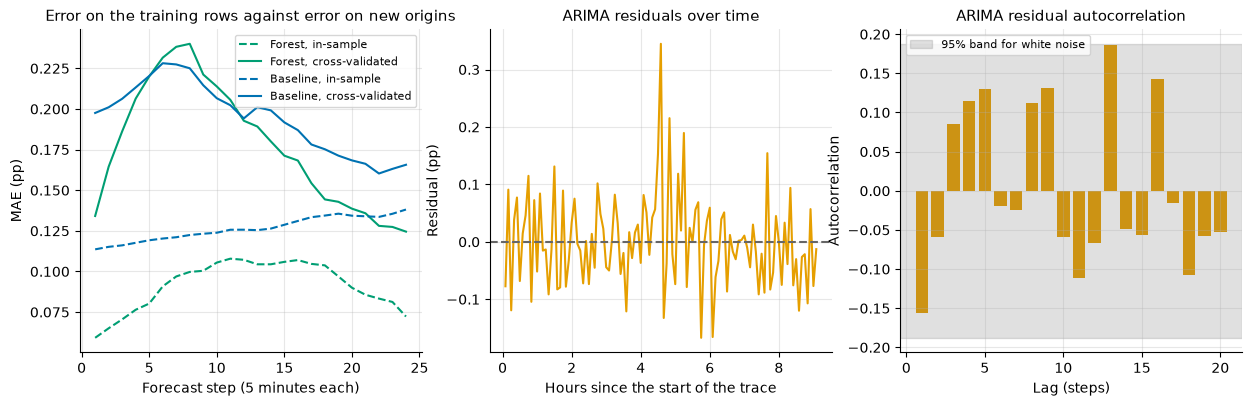

In [21]:
fit_by_step = pd.DataFrame(
    {
        "Forest, in-sample": forest_fit["forest"],
        "Forest, cross-validated": horizon_mae[models.FOREST_NAME],
        "Baseline, in-sample": forest_fit["baseline"],
        "Baseline, cross-validated": horizon_mae[models.BASELINE_NAME],
    }
)
an.save_table(fit_by_step.round(4), "model_fit_by_step")
display(fit_by_step.loc[list(REPORT_STEPS)].round(3))

residual_hours = hours[-len(residuals):]
residual_acf = an.autocorrelation_table(residuals, nlags=20)["acf"].iloc[1:]
band = an.white_noise_band(len(residuals))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(fit_by_step.index, fit_by_step["Forest, in-sample"], color=an.PALETTE["green"], linestyle="--", label="Forest, in-sample")
axes[0].plot(fit_by_step.index, fit_by_step["Forest, cross-validated"], color=an.PALETTE["green"], label="Forest, cross-validated")
axes[0].plot(fit_by_step.index, fit_by_step["Baseline, in-sample"], color=an.PALETTE["blue"], linestyle="--", label="Baseline, in-sample")
axes[0].plot(fit_by_step.index, fit_by_step["Baseline, cross-validated"], color=an.PALETTE["blue"], label="Baseline, cross-validated")
axes[0].set(xlabel="Forecast step (5 minutes each)", ylabel="MAE (pp)", title="Error on the training rows against error on new origins")
axes[0].legend(fontsize=8)
axes[1].plot(residual_hours, residuals.to_numpy(), color=an.PALETTE["orange"])
axes[1].axhline(0, color=an.PALETTE["grey"], linestyle="--")
axes[1].set(xlabel="Hours since the start of the trace", ylabel="Residual (pp)", title="ARIMA residuals over time")
axes[2].bar(residual_acf.index, residual_acf.to_numpy(), color=an.PALETTE["orange"])
axes[2].axhspan(-band, band, color=an.PALETTE["grey"], alpha=0.2, label="95% band for white noise")
axes[2].set(xlabel="Lag (steps)", ylabel="Autocorrelation", title="ARIMA residual autocorrelation")
axes[2].legend(fontsize=8)
an.save_figure(fig, "model_fit_check")
plt.show()


**Finding.** The totals: ARIMA's in-sample one-step MAE is 0.061 against 0.082 cross-validated (ratio 1.36), the forest's is 0.092 against 0.177 (ratio 1.94) and the baseline's is 0.126 against 0.194 (ratio 1.54). In the left panel the forest's in-sample error lies below its cross-validated error at every step. The gap is widest at the early steps (0.059 against 0.134 at step 1, 0.091 against 0.232 at step 6) and narrowest at the end (0.072 against 0.125 at step 24). The baseline shows a gap as well (0.114 against 0.198 at step 1, 0.138 against 0.166 at step 24), and the forest's in-sample error is below the baseline's at every step. In the middle panel the ARIMA residuals scatter around zero with no trend and no long run of one sign; the one large spike is near hour 4.6, when the level rose. In the right panel every autocorrelation bar of the residuals lies inside the 95% band (the tallest, at lag 13, just reaches its edge), which agrees with the Ljung-Box p-values of 0.19, 0.31 and 0.25 at lags 5, 10 and 20: no significant autocorrelation is left.

**So what.** ARIMA neither underfits nor overfits. Its residuals look like noise, so there is no pattern left for a larger model to use, and its error on new origins is only about a third above its error on the fitted data, a normal gap because forecasting new data is harder than describing old data. The forest fits its training rows clearly better than it forecasts new origins (more than twice as well at steps 1 and 6), which is typical of tree models and a sign of some overfitting. Three facts keep this acceptable. The baseline, which has almost nothing to overfit, shows a gap too, so part of every gap comes from the harder-to-forecast level shift in the validation data and not only from memorising. Smaller leaves did not lower the cross-validated error (section 5), so more regularisation would not help. The forest is not underfitting either: it fits the training rows better than the baseline at every step, and only at a 30% leaf share does it fall back to the baseline's error. With 110 points these checks cannot rule out mild overfitting, which is one more reason to treat the small MAE difference between the models as a tie.

## 7. The vm-count series

Why this section exists: the assignment asks for forecasts of two series, `aggregate_cpu_utilization` (sections 1 to 6) and `active_vm_count`. The EDA found that `active_vm_count` never changes in the training window, so no model is needed for it. This section confirms that with the same rolling-origin test, so the choice of forecaster for the second series rests on a result and not on an assumption.

What is checked: the same rolling-origin test is run on `active_vm_count` with three simple forecasters (repeat the last value, repeat the history mean, and the baseline of section 2).

In [22]:
count_series = train[ACTIVE_VM_COUNT].astype(float)
count_forecasters = {"Persistence": models.persistence, "History mean": models.history_mean, models.BASELINE_NAME: models.baseline_forecast}
count_result = ev.run_cv(count_series, count_forecasters)
count_table = ev.metrics_table(count_result, reference="Persistence")[["MAE", "RMSE"]]
an.save_table(count_table, "model_count_cv")
display(count_table)

,MAE,RMSE
Persistence,0.0,0.0
History mean,0.0,0.0
Baseline,0.0,0.0


**Finding.** `active_vm_count` is constant in the training window, so persistence, the history mean and the baseline all have an MAE and RMSE of exactly 0 at every origin.

**So what.** There is nothing to learn. Persistence (copy the last value) is chosen for this series because it is exact here, and it is also the right default if the count ever changes in other data. Relative metrics are not defined when the baseline error is zero, so only absolute errors are reported for this series. The EDA data-quality check found the count constant at every timestamp.

## 8. The three models compared

In [23]:
final_table = metrics.loc[candidates].join(horizon_mae.loc[list(REPORT_STEPS), candidates].T.add_prefix("MAE step "))
an.save_table(final_table, "model_final_metrics")
display(final_table.round(3))

,MAE,RMSE,MAE ratio,Improvement %,High-load MAE,High-load RMSE,High-load bias,Fold MAE std,Folds better %,MAE step 1,MAE step 6,MAE step 12,MAE step 24
Baseline,0.194,0.229,1.000,0.000,0.294,0.326,0.294,0.053,0.000,0.198,0.228,0.194,0.166
ARIMA,0.179,0.213,0.919,8.130,0.238,0.284,0.223,0.058,66.667,0.082,0.195,0.196,0.175
Random forest,0.177,0.232,0.913,8.676,0.304,0.338,0.299,0.090,53.846,0.134,0.232,0.193,0.125


### Metrics of the three models

Rolling-origin cross-validation on the 110 training points, 39 origins, 24 steps each. Lower is better except for "Improvement %" and "Folds better %". The baseline is the reference for the ratio, the improvement and the share of better folds, so its values there are 1, 0 and 0. Bias is actual minus forecast, so a positive value means forecasts that are too low. High-load metrics use only the target values at or above the 80th percentile of the history at that origin (the peaks). "Folds better %" is the share of the 39 origins at which the model's MAE is lower than the baseline's.

| Metric | Baseline | ARIMA | Random forest | Best | Middle | Worst |
|---|---|---|---|---|---|---|
| MAE | 0.194 | 0.179 | 0.177 | Random forest | ARIMA | Baseline |
| RMSE | 0.229 | 0.213 | 0.232 | ARIMA | Baseline | Random forest |
| MAE ratio | 1.000 | 0.919 | 0.913 | Random forest | ARIMA | Baseline |
| Improvement % | 0.000 | 8.130 | 8.676 | Random forest | ARIMA | Baseline |
| High-load MAE | 0.294 | 0.238 | 0.304 | ARIMA | Baseline | Random forest |
| High-load RMSE | 0.326 | 0.284 | 0.338 | ARIMA | Baseline | Random forest |
| High-load bias | 0.294 | 0.223 | 0.299 | ARIMA | Baseline | Random forest |
| Fold MAE std | 0.053 | 0.058 | 0.090 | Baseline | ARIMA | Random forest |
| Folds better % | 0.000 | 66.667 | 53.846 | ARIMA | Random forest | Baseline |
| MAE step 1 | 0.198 | 0.082 | 0.134 | ARIMA | Random forest | Baseline |
| MAE step 6 | 0.228 | 0.195 | 0.232 | ARIMA | Baseline | Random forest |
| MAE step 12 | 0.194 | 0.196 | 0.193 | Random forest | Baseline | ARIMA |
| MAE step 24 | 0.166 | 0.175 | 0.125 | Random forest | Baseline | ARIMA |

Rank counts across the 13 rows (best): Baseline 1, ARIMA 7, Random forest 5.

### Metric by metric

**MAE, MAE ratio and improvement (average error over all 24 steps).** The random forest is best (0.177, 8.7% better than the baseline), ARIMA is in the middle (0.179, 8.1%) and the baseline is worst (0.194). The forest wins on average because the average includes the far end of the horizon, where it is clearly ahead (0.125 at step 24 against 0.175 for ARIMA). ARIMA is close behind (0.179 against 0.177) because its large advantage at the first steps cancels most of that. The baseline is worst because it ignores where the series is now, but it is within about 9% of both models since its level and hourly pattern are right. What it means: both models add a real but modest gain, and the gap between them is inside the noise, so treat it as a tie.

**RMSE.** ARIMA is best (0.213), the baseline is in the middle (0.229) and the random forest is worst (0.232), but the forest and the baseline are effectively tied; ARIMA is the one clearly ahead. RMSE squares the errors, so a few large misses count a lot. ARIMA adapts to a level shift within a few steps and so avoids the largest misses. The baseline is in the middle because it never fits itself badly, it just misses every level shift. The forest is slightly worse than the baseline because a tree can only output corrections it has seen during training; when the level moves somewhere new its forecast can be far off (see its climb at the last origins in section 6), which gives it some large errors even though its average error is the lowest. What it means: the forest probably has many small gains and a few large losses.

**High-load MAE, RMSE and bias (values at or above the 80th percentile of the history).** ARIMA is best on all three (0.238, 0.284 and 0.223), the baseline is in the middle (0.294, 0.326 and 0.294) and the random forest is worst (0.304, 0.338 and 0.299). All three forecast peaks too low (the bias is positive). The baseline and the forest are anchored to the long-run mean, and a peak is by definition above the usual level; the forest also cannot output a correction larger than the ones it has seen. ARIMA starts from the latest value, which is already elevated at a peak, so it gets part of the way up. The reference persistence, which only copies the latest value, is better still on peaks (MAE 0.234, bias 0.107, from section 6), but it is worse overall (MAE 0.238), so it is not a candidate. What it means: none of the models removes the under-forecast at peaks, ARIMA reduces it the most of the three, and a safety margin is still needed for capacity planning (step 7).

**Fold MAE std (how much the error changes between origins; lower is steadier).** The baseline is best (0.053), ARIMA is in the middle (0.058) and the random forest is worst (0.090). The baseline gives nearly the same forecast shape every time, so its error changes only with the data. The forest is refitted on a different small set of rows at every origin (very few at the start), so its forecasts, and its errors, swing more. What it means: the forest's average is good but it is the least predictable from one forecast to the next.

**Folds better than the baseline.** ARIMA is best (66.7% of origins), the random forest is in the middle (53.8%) and the baseline is last by definition (0%, it is the reference). What it means: ARIMA's gain is consistent, two origins in three, while the forest's is close to a coin flip with some large wins.

**MAE by forecast step.**
- Step 1 (5 minutes ahead): ARIMA is best (0.082), the forest is in the middle (0.134) and the baseline is worst (0.198). The latest deviation from the profile strongly predicts the next value, and ARIMA uses it directly; the forest approximates the same relationship with steps and few rows, so it is coarser; the baseline ignores it.
- Step 6: ARIMA is best (0.195), the baseline is in the middle (0.228) and the forest is worst (0.232). The carry-over from the latest value is fading, and the forest is slightly worse than the baseline here.
- Step 12: the forest (0.193), the baseline (0.194) and ARIMA (0.196) tie. At one hour ahead the recent data have little left to offer.
- Step 24 (2 hours ahead): the forest is best (0.125), the baseline is in the middle (0.166) and ARIMA is worst (0.175). The forest learned that a high recent hour is followed by a below-baseline value two hours later; ARIMA's carry-over has died out and it only adds estimation noise to the baseline.

### Best overall: ARIMA(1,0,0) with the hourly profile

It is best on 7 of the 13 rows: RMSE, all three high-load measures, the share of better folds and the MAE at steps 1 and 6. It is second on the average MAE (0.179 against 0.177 for the forest) and second on stability. The forest wins the average and the far end of the horizon but is the worst on RMSE, on peaks and on stability, which are the things a capacity team depends on. The baseline is a strong floor: both models beat it by less than 10% on MAE. Caveats: 39 overlapping origins, differences of a few thousandths of a pp in MAE are inside the noise, ARIMA fell back to the baseline at one origin, and the tuning used the same cross-validation, so the numbers are slightly optimistic. The final 24 points are used only once, at the end, to check this choice.

### Decisions carried forward
1. ARIMA(1,0,0) with the hourly profile is the recommended model on this evidence; the random forest (100 trees, 15% leaf share, inputs lag_1, lag_12 and mean_last_hour, learning the correction to the baseline) is the machine-learning model and the better far-horizon forecaster. The baseline stays the reference.
2. `active_vm_count` uses persistence.
3. Every model under-forecasts peaks, so intervals and a headroom margin are built from the cross-validation errors in step 7.

### Limitations
- 110 training points and heavily overlapping origins: small differences are not statistically settled.
- The hourly pattern comes from only about 9 cycles, and daily or weekly patterns cannot be tested.
- Tuning and model comparison used the same cross-validation, which is mildly optimistic.
- The design choices (an hourly profile, no differencing) came from the EDA on all 110 training points, so the early origins are not completely blind to the pattern they are tested on.
- The forest's training targets subtract a baseline fitted on the same history, so they are slightly smaller than the errors the baseline makes on new data. No future value is involved, but it can make the forest's corrections a little too small.
- Early origins leave the 24-step forest only about a dozen training rows.